<a href="https://colab.research.google.com/github/mandakamal/Project_GempaSumatera_Kel1/blob/main/Analisis_Deskriptif_Gempa_Sumatera_revisi.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ANALISIS DESKRIPTIF KARAKTERISTIK GEMPA BUMI DI PULAU SUMATERA BERDASARKAN MAGNITUDO DAN KEDALAMAN


In [ ]:
from pathlib import Path
import pandas as pd
import numpy as np
from google.colab import files
import os

# Periksa apakah file sudah ada di lingkungan kerja saat ini
target_file = '3TIA_01_Data_GempaBumi_BMKG(1).xlsx'
if not os.path.exists(target_file):
    print("Silakan pilih file data gempa bumi BMKG dari PC Anda:")
    uploaded = files.upload()
else:
    print(f"File '{target_file}' sudah tersedia dan siap digunakan!")


Silakan pilih file data gempa bumi BMKG dari PC Anda:


Saving 3TIA_01_Data_GempaBumi_BMKG.xlsx to 3TIA_01_Data_GempaBumi_BMKG (1).xlsx


## 1. Sumber, struktur, dan deskripsi data

Sumber BMKG diambil dari sheet `Dataset_Info` pada berkas pengguna. Berkas tidak mencantumkan URL katalog, tanggal pengunduhan, atau jenis magnitudo (misalnya ML/Mw); informasi tersebut tidak dibuat-buat. Tautan USGS pada akhir notebook hanya mendukung konsep, bukan sumber rekaman analisis.

Pembersihan dimulai dari `Raw_Data` agar ID dan nilai asli dapat ditelusuri. `Data_Clean` yang sudah tersedia tidak digabungkan dengan data mentah karena berisi rekaman yang sama. Jumlah kolom fisik, kolom inti, dan variabel analisis dibedakan.


In [ ]:
FILE_EXCEL = '/content/3TIA_01_Data_GempaBumi_BMKG.xlsx'
ID_DIKELUARKAN_SETELAH_VERIFIKASI = []

xls = pd.ExcelFile(FILE_EXCEL)
raw = pd.read_excel(xls, sheet_name='Raw_Data', dtype={'Event No.': 'string'})
info_sumber = pd.read_excel(xls, sheet_name='Dataset_Info')
display(info_sumber)
display(pd.DataFrame({
    'Elemen': ['Sheet yang tersedia', 'Banyak rekaman mentah', 'Jumlah kolom fisik',
               'Jumlah kolom inti termasuk nomor urut dan ID', 'Jumlah variabel utama'],
    'Nilai': [', '.join(xls.sheet_names), len(raw), raw.shape[1], 8, 2]
}))
display(raw.head(10))

,Informasi,Keterangan
0,Nama Dataset,Data Historis Gempa Bumi Pulau Sumatera
1,Sumber Data,"BMKG (Badan Meteorologi, Klimatologi, dan Geofisika)"
2,Nama Sheet Sumber,datagempa
3,Periode Data pada File,01 September 2025 – 26 September 2026 (UTC)
4,Jumlah Observasi,2597
5,Jumlah Variabel,8
6,Objek Penelitian,Kejadian gempa bumi yang tercatat pada dataset BMKG
7,Variabel Utama,Magnitude dan Depth_km
8,Variabel Pendukung,"Date_Time_UTC, Latitude, Longitude, Location"
9,Missing Value,Tidak ditemukan pada 2597 observasi untuk variabel yang diperiksa


,Elemen,Nilai
0,Sheet yang tersedia,"Raw_Data, Data_Clean, Keterangan_Variabel, Dataset_Info, Quality_Check"
1,Banyak rekaman mentah,2597
2,Jumlah kolom fisik,10
3,Jumlah kolom inti termasuk nomor urut dan ID,8
4,Jumlah variabel utama,2


,No.,Event No.,Date time (UTC),Latitude,Longitude,Magnitude,Depth (km),Location,Tipe Data,Jenis Variabel
0,1,120210,2025-09-01 21:32:18.000000,2.4881,98.6224,2.0000,2.6500,"Northern Sumatra, Indonesia",NaN,NaN
1,2,123336,2025-09-02 00:28:28.000000,-2.4933,101.9029,3.2000,138.6900,"Southern Sumatra, Indonesia",NaN,NaN
2,3,123337,2025-09-02 00:28:28.000000,-2.4196,101.9073,3.0000,133.4000,"Southern Sumatra, Indonesia",NaN,NaN
3,4,123358,2025-09-02 08:34:30.000000,-4.3935,103.7140,2.5000,121.4200,"Southern Sumatra, Indonesia",NaN,NaN
4,5,123359,2025-09-02 09:13:24.000000,3.8284,96.6274,2.6000,20.1700,"Northern Sumatra, Indonesia",NaN,NaN
5,6,123377,2025-09-02 13:22:23.000000,-4.6137,103.0592,2.5000,75.1100,"Southern Sumatra, Indonesia",NaN,NaN
6,7,123410,2025-09-02 21:29:02.000000,0.5180,98.7113,2.6000,2.6000,"Northern Sumatra, Indonesia",NaN,NaN
7,8,123425,2025-09-02 23:43:05.000000,-4.2238,102.4353,2.9000,45.6000,"Southern Sumatra, Indonesia",NaN,NaN
8,9,126396,2025-09-03 00:29:46.000000,3.4589,97.8207,2.8000,8.0000,"Northern Sumatra, Indonesia",NaN,NaN
9,10,126407,2025-09-03 03:50:18.000000,1.6163,99.0962,3.3000,10.0000,"Northern Sumatra, Indonesia",NaN,NaN


## 2. Tipe dan skala pengukuran

Magnitudo diperlakukan sebagai data numerik kontinu dengan **skala interval logaritmik**, bukan ordinal atau rasio. Nilai magnitudo 6 tidak berarti dua kali magnitudo 3 dalam energi. Rata-rata magnitudo di sini hanya rata-rata angka yang tercatat, bukan rata-rata energi. Kedalaman memiliki nol bermakna sehingga berskala rasio. Jenis magnitudo tidak tersedia sehingga keseragaman ML/Mw belum dapat diperiksa.


In [ ]:
kamus = pd.DataFrame([
    ['Magnitude', 'Numerik kontinu', 'Interval (logaritmik)', 'Nilai magnitudo', 'Analisis utama'],
    ['Depth_km', 'Numerik kontinu', 'Rasio', 'km', 'Analisis utama'],
    ['Date_Time_UTC', 'Tanggal/waktu', 'Interval', 'UTC', 'Ringkasan waktu'],
    ['Latitude', 'Numerik kontinu', 'Interval (koordinat)', 'Derajat', 'Pemeriksaan lokasi'],
    ['Longitude', 'Numerik kontinu', 'Interval (koordinat)', 'Derajat', 'Pemeriksaan lokasi'],
    ['Location', 'Kategorikal', 'Nominal', 'Nama wilayah', 'Ringkasan lokasi'],
    ['Event_No', 'Teks / pengenal', 'Nominal', 'ID', 'Pemeriksaan rekaman ganda'],
    ['No', 'Nomor urut administratif', 'Bukan variabel analisis', '-', 'Penelusuran baris'],
    ['Kategori kedalaman', 'Kategorikal berurutan', 'Ordinal', 'Diturunkan dari km', 'Tabel frekuensi']
], columns=['Variabel', 'Jenis data', 'Skala pengukuran', 'Satuan / bentuk', 'Peran'])
display(kamus)


,Variabel,Jenis data,Skala pengukuran,Satuan / bentuk,Peran
0,Magnitude,Numerik kontinu,Interval (logaritmik),Nilai magnitudo,Analisis utama
1,Depth_km,Numerik kontinu,Rasio,km,Analisis utama
2,Date_Time_UTC,Tanggal/waktu,Interval,UTC,Ringkasan waktu
3,Latitude,Numerik kontinu,Interval (koordinat),Derajat,Pemeriksaan lokasi
4,Longitude,Numerik kontinu,Interval (koordinat),Derajat,Pemeriksaan lokasi
5,Location,Kategorikal,Nominal,Nama wilayah,Ringkasan lokasi
6,Event_No,Teks / pengenal,Nominal,ID,Pemeriksaan rekaman ganda
7,No,Nomor urut administratif,Bukan variabel analisis,-,Penelusuran baris
8,Kategori kedalaman,Kategorikal berurutan,Ordinal,Diturunkan dari km,Tabel frekuensi


## 3. Pembersihan data dan jejak pemeriksaan

Kolom `Tipe Data` dan `Jenis Variabel` bukan pengukuran per kejadian: hampir seluruh isinya kosong dan terdapat teks judul di satu baris. Keduanya dikeluarkan dari analisis, **baris kejadiannya tetap dipertahankan**. Nama kolom dan spasi dirapikan; nilai numerik dan waktu dikonversi tanpa pembulatan.

Baris tanpa magnitudo/kedalaman yang valid atau dengan kedalaman negatif tidak masuk analisis utama. Tidak ada imputasi rata-rata. Magnitudo negatif tidak otomatis dianggap salah. Data berulang hanya dihapus jika semua kolom inti selain nomor urut sama; ID berulang dengan isi berbeda ditandai dan dihentikan untuk ditinjau. Waktu/koordinat yang bermasalah ditandai, bukan menjadi alasan otomatis menghapus magnitudo/kedalaman yang valid.


In [ ]:
rename = {'No.':'No', 'Event No.':'Event_No', 'Date time (UTC)':'Date_Time_UTC',
          'Depth (km)':'Depth_km'}
kolom_inti = ['No','Event_No','Date_Time_UTC','Latitude','Longitude','Magnitude','Depth_km','Location']
data = raw.rename(columns=lambda c: str(c).strip()).rename(columns=rename)[kolom_inti].copy()
for c in ['Event_No', 'Location']:
    data[c] = data[c].astype('string').str.strip().replace('', pd.NA)
angka = ['Latitude','Longitude','Magnitude','Depth_km']
for c in angka:
    data[c] = pd.to_numeric(data[c].astype('string').str.replace(',', '.', regex=False), errors='coerce')
    data[c] = data[c].replace([np.inf, -np.inf], np.nan).astype(float)
data['Date_Time_UTC'] = pd.to_datetime(data['Date_Time_UTC'], errors='coerce', format='mixed', utc=True)

kualitas = pd.DataFrame({
    'Variabel': kolom_inti,
    'Kosong pada data mentah': [raw.rename(columns=rename)[c].isna().sum() for c in kolom_inti],
    'Kosong / gagal konversi': [data[c].isna().sum() for c in kolom_inti],
    'Tipe setelah konversi': [str(data[c].dtype) for c in kolom_inti]
})
display(kualitas)

alasan = pd.Series('', index=data.index, dtype='string')
def tandai(mask, pesan):
    alasan.loc[mask] = alasan.loc[mask] + pesan + '; '
tandai(data[['Magnitude','Depth_km']].isna().any(axis=1), 'Magnitudo/kedalaman tidak valid')
tandai(data['Depth_km'].lt(0), 'Kedalaman negatif')
duplikat = data.duplicated(subset=[c for c in kolom_inti if c != 'No'], keep='first')
tandai(duplikat, 'Duplikat identik selain nomor urut')
tandai(data['Event_No'].isin(ID_DIKELUARKAN_SETELAH_VERIFIKASI), 'Dikeluarkan setelah verifikasi pengguna')
data_dikeluarkan = data.loc[alasan.ne('')].copy()
data_dikeluarkan['Alasan'] = alasan.loc[alasan.ne('')]
bersih = data.loc[alasan.eq('')].copy()
konflik_id = bersih.loc[bersih['Event_No'].notna() & bersih['Event_No'].duplicated(keep=False)]
if not konflik_id.empty:
    display(konflik_id)
    raise ValueError('ID berulang dengan isi berbeda: verifikasi dahulu; jangan pilih versi secara otomatis.')
if bersih.empty:
    raise ValueError('Tidak ada data yang memenuhi syarat analisis.')

display(pd.DataFrame({
    'Tahap': ['Rekaman awal', 'Dikeluarkan (gabungan alasan, tanpa hitung ganda)', 'Rekaman dianalisis',
              'Waktu tidak valid (tidak masuk ringkasan waktu)', 'Koordinat hilang / di luar rentang global'],
    'Jumlah': [len(raw), len(data_dikeluarkan), len(bersih), bersih['Date_Time_UTC'].isna().sum(),
               (~bersih['Latitude'].between(-90,90) | ~bersih['Longitude'].between(-180,180)).sum()]
}))
display(data_dikeluarkan)
display(bersih.head(10))


,Variabel,Kosong pada data mentah,Kosong / gagal konversi,Tipe setelah konversi
0,No,0,0,int64
1,Event_No,0,0,string
2,Date_Time_UTC,0,0,"datetime64[ns, UTC]"
3,Latitude,0,0,float64
4,Longitude,0,0,float64
5,Magnitude,0,0,float64
6,Depth_km,0,0,float64
7,Location,0,0,string


,Tahap,Jumlah
0,Rekaman awal,2597
1,"Dikeluarkan (gabungan alasan, tanpa hitung ganda)",0
2,Rekaman dianalisis,2597
3,Waktu tidak valid (tidak masuk ringkasan waktu),0
4,Koordinat hilang / di luar rentang global,0


,No,Event_No,Date_Time_UTC,Latitude,Longitude,Magnitude,Depth_km,Location,Alasan


,No,Event_No,Date_Time_UTC,Latitude,Longitude,Magnitude,Depth_km,Location
0,1,120210,2025-09-01 21:32:18+00:00,2.4881,98.6224,2.0000,2.6500,"Northern Sumatra, Indonesia"
1,2,123336,2025-09-02 00:28:28+00:00,-2.4933,101.9029,3.2000,138.6900,"Southern Sumatra, Indonesia"
2,3,123337,2025-09-02 00:28:28+00:00,-2.4196,101.9073,3.0000,133.4000,"Southern Sumatra, Indonesia"
3,4,123358,2025-09-02 08:34:30+00:00,-4.3935,103.7140,2.5000,121.4200,"Southern Sumatra, Indonesia"
4,5,123359,2025-09-02 09:13:24+00:00,3.8284,96.6274,2.6000,20.1700,"Northern Sumatra, Indonesia"
5,6,123377,2025-09-02 13:22:23+00:00,-4.6137,103.0592,2.5000,75.1100,"Southern Sumatra, Indonesia"
6,7,123410,2025-09-02 21:29:02+00:00,0.5180,98.7113,2.6000,2.6000,"Northern Sumatra, Indonesia"
7,8,123425,2025-09-02 23:43:05+00:00,-4.2238,102.4353,2.9000,45.6000,"Southern Sumatra, Indonesia"
8,9,126396,2025-09-03 00:29:46+00:00,3.4589,97.8207,2.8000,8.0000,"Northern Sumatra, Indonesia"
9,10,126407,2025-09-03 03:50:18+00:00,1.6163,99.0962,3.3000,10.0000,"Northern Sumatra, Indonesia"


## 4. Pemeriksaan label wilayah dan batas analisis

Dataset mencakup label Sumatera, lepas pantai, dan Selat Sunda; ini **bukan hanya kejadian di daratan pulau**. Dua label pada berkas awal, `West Papua Region, Indonesia` dan `Bali Sea`, memerlukan konfirmasi karena koordinat yang tercatat berada di sekitar rentang koordinat rekaman Sumatera lainnya. Notebook tidak mengganti label atau menghapus baris hanya berdasarkan nama wilayah.

Seluruh rekaman numerik valid dari berkas digunakan secara transparan. Tabel berikut memisahkan rekaman dengan label yang perlu diperiksa. Untuk klaim batas daratan Sumatera secara ketat, diperlukan batas geografis dan verifikasi katalog. Rentang koordinat saja tidak membuktikan keanggotaan wilayah.


In [ ]:
label_sesuai_cakupan = ['Northern Sumatra, Indonesia', 'Southern Sumatra, Indonesia',
    'Off West Coast of Northern Sumatra', 'Southwest of Sumatra, Indonesia', 'Sunda Strait, Indonesia']
bersih['Perlu_verifikasi_lokasi'] = ~bersih['Location'].isin(label_sesuai_cakupan)
audit_lokasi = bersih.loc[bersih['Perlu_verifikasi_lokasi'], kolom_inti]
display(audit_lokasi)
resume_lokasi = (bersih.groupby('Location', dropna=False).agg(
    Jumlah=('Magnitude','size'), Rerata_magnitudo=('Magnitude','mean'),
    Rerata_kedalaman_km=('Depth_km','mean'), Kedalaman_maks_km=('Depth_km','max'))
    .sort_values('Jumlah', ascending=False).reset_index())
resume_lokasi['Persentase (%)'] = resume_lokasi['Jumlah'] / len(bersih) * 100
display(resume_lokasi)


,No,Event_No,Date_Time_UTC,Latitude,Longitude,Magnitude,Depth_km,Location
351,352,151703,2025-09-26 15:03:19+00:00,-5.5078,104.5018,2.5000,8.8200,"West Papua Region, Indonesia"
422,423,152330,2025-09-30 21:02:48+00:00,-5.7892,104.7005,2.0000,2.6700,Bali Sea


,Location,Jumlah,Rerata_magnitudo,Rerata_kedalaman_km,Kedalaman_maks_km,Persentase (%)
0,"Northern Sumatra, Indonesia",1345,2.8200,26.9146,221.9100,51.7905
1,"Southern Sumatra, Indonesia",1136,2.8844,29.6629,356.4300,43.7428
2,Off West Coast of Northern Sumatra,84,3.7002,18.8867,87.3500,3.2345
3,"Southwest of Sumatra, Indonesia",23,3.9243,26.1813,74.3200,0.8856
4,"Sunda Strait, Indonesia",7,3.1314,102.9800,138.7700,0.2695
5,Bali Sea,1,2.0000,2.6700,2.6700,0.0385
6,"West Papua Region, Indonesia",1,2.5000,8.8200,8.8200,0.0385


## 5. Ukuran statistika deskriptif dan alasan pemilihan

Digunakan **16 ukuran** bila Q2/median dihitung satu kali: count, mean, median, modus, standar deviasi, varians, Q1, Q3, IQR, skewness, kurtosis, minimum, maksimum, range, frekuensi modus, dan CV (kedalaman). Ini melampaui minimum enam dan lebih dari 50% daftar yang diberikan. Frekuensi modus adalah pelengkap; tanpa ukuran ini pun syarat terpenuhi.

Standar deviasi dan varians memakai pembagi **n−1 (`ddof=1`)** sebagai ringkasan sampel; penggunaan rumus ini bukan uji inferensial. Skewness/kurtosis memakai koreksi bawaan pandas dan kurtosis **excess** (acuan normal = 0); tidak dilakukan uji normalitas. Kuartil menggunakan interpolasi linear. Pembulatan hanya pada tampilan.


In [ ]:
alasan_statistik = pd.DataFrame([
 ['Count (n)', 'Banyak nilai valid', 'Menjelaskan banyak kejadian yang mendasari ringkasan.'],
 ['Mean', 'Jumlah nilai / n', 'Menunjukkan pusat aritmetika; sensitif terhadap nilai ekstrem.'],
 ['Median / Q2', 'Persentil ke-50', 'Menunjukkan nilai tengah yang lebih tahan terhadap nilai ekstrem.'],
 ['Modus', 'Semua nilai dengan frekuensi tertinggi', 'Mengetahui nilai yang paling sering tercatat; dipengaruhi ketelitian pencatatan.'],
 ['Frekuensi modus', 'Banyak kemunculan setiap nilai modus', 'Menunjukkan seberapa sering nilai modus muncul.'],
 ['Standar deviasi', 'Akar varians, ddof=1', 'Mengukur penyebaran dalam satuan asli variabel.'],
 ['Varians', 'Jumlah kuadrat selisih dari mean / (n−1)', 'Mengukur penyebaran kuadrat; satuan magnitudo² atau km².'],
 ['Q1', 'Persentil ke-25', 'Menentukan batas bawah 50% bagian tengah data.'],
 ['Q3', 'Persentil ke-75', 'Menentukan batas atas 50% bagian tengah data.'],
 ['IQR', 'Q3 − Q1', 'Mengukur lebar 50% bagian tengah, relatif tahan terhadap nilai ekstrem.'],
 ['Skewness', 'pandas.Series.skew()', 'Mendeskripsikan arah kemencengan distribusi, tanpa uji signifikansi.'],
 ['Kurtosis (excess)', 'pandas.Series.kurt()', 'Mendeskripsikan karakter ekor distribusi; bukan ukuran bahaya gempa.'],
 ['Minimum', 'Nilai terkecil', 'Menunjukkan batas bawah nilai yang diamati.'],
 ['Maksimum', 'Nilai terbesar', 'Menunjukkan batas atas nilai yang diamati.'],
 ['Range', 'Maksimum − minimum', 'Menunjukkan bentang total; sensitif terhadap nilai ekstrem.'],
 ['CV kedalaman (%)', 'SD / mean × 100', 'Mengukur keragaman relatif kedalaman yang berskala rasio.']
], columns=['Statistik', 'Definisi / perhitungan', 'Alasan digunakan'])
display(alasan_statistik)
display(pd.DataFrame([
 ['SE', 'Tidak digunakan', 'Fokus pada sebaran kejadian; SE membahas ketidakpastian rata-rata dan tidak diperlukan untuk tujuan ini.'],
 ['Jumlah / sum magnitudo', 'Tidak digunakan', 'Penjumlahan magnitudo bukan total energi gempa.'],
 ['Jumlah / sum kedalaman', 'Tidak digunakan', 'Total kedalaman antar-kejadian tidak memberikan karakteristik fisik yang berguna.'],
 ['CV magnitudo', 'Tidak digunakan', 'Magnitudo logaritmik tidak memiliki nol absolut seperti skala rasio.']
], columns=['Ukuran', 'Keputusan', 'Alasan']))


,Statistik,Definisi / perhitungan,Alasan digunakan
0,Count (n),Banyak nilai valid,Menjelaskan banyak kejadian yang mendasari ringkasan.
1,Mean,Jumlah nilai / n,Menunjukkan pusat aritmetika; sensitif terhadap nilai ekstrem.
2,Median / Q2,Persentil ke-50,Menunjukkan nilai tengah yang lebih tahan terhadap nilai ekstrem.
3,Modus,Semua nilai dengan frekuensi tertinggi,Mengetahui nilai yang paling sering tercatat; dipengaruhi ketelitian pencatatan.
4,Frekuensi modus,Banyak kemunculan setiap nilai modus,Menunjukkan seberapa sering nilai modus muncul.
5,Standar deviasi,"Akar varians, ddof=1",Mengukur penyebaran dalam satuan asli variabel.
6,Varians,Jumlah kuadrat selisih dari mean / (n−1),Mengukur penyebaran kuadrat; satuan magnitudo² atau km².
7,Q1,Persentil ke-25,Menentukan batas bawah 50% bagian tengah data.
8,Q3,Persentil ke-75,Menentukan batas atas 50% bagian tengah data.
9,IQR,Q3 − Q1,"Mengukur lebar 50% bagian tengah, relatif tahan terhadap nilai ekstrem."


,Ukuran,Keputusan,Alasan
0,SE,Tidak digunakan,Fokus pada sebaran kejadian; SE membahas ketidakpastian rata-rata dan tidak diperlukan untuk tujuan ini.
1,Jumlah / sum magnitudo,Tidak digunakan,Penjumlahan magnitudo bukan total energi gempa.
2,Jumlah / sum kedalaman,Tidak digunakan,Total kedalaman antar-kejadian tidak memberikan karakteristik fisik yang berguna.
3,CV magnitudo,Tidak digunakan,Magnitudo logaritmik tidak memiliki nol absolut seperti skala rasio.


In [ ]:
def statistik_deskriptif(s, gunakan_cv=False):
    s = s.dropna()
    q1, q2, q3 = s.quantile([0.25, 0.5, 0.75], interpolation='linear')
    frek = s.value_counts()
    frek_tertinggi = int(frek.max())
    modus = s.mode().tolist()
    teks_modus = ', '.join(f'{v:g}' for v in modus) if frek_tertinggi > 1 else 'Tidak ada modus berulang'
    return pd.Series({
        'Count (n)': len(s), 'Mean': s.mean(), 'Median / Q2': q2,
        'Modus': teks_modus, 'Frekuensi modus': frek_tertinggi,
        'Standar deviasi (ddof=1)': s.std(ddof=1), 'Varians (ddof=1)': s.var(ddof=1),
        'Q1': q1, 'Q3': q3, 'IQR': q3-q1, 'Skewness': s.skew(),
        'Kurtosis (excess)': s.kurt(), 'Minimum': s.min(), 'Maksimum': s.max(),
        'Range': s.max()-s.min(),
        'CV (%)': s.std(ddof=1)/s.mean()*100 if gunakan_cv and s.mean()>0 else np.nan
    })

ringkasan_statistik = pd.DataFrame({
    'Magnitudo': statistik_deskriptif(bersih['Magnitude']),
    'Kedalaman (km)': statistik_deskriptif(bersih['Depth_km'], gunakan_cv=True)
}).rename_axis('Statistik').reset_index()
tampilan_statistik = ringkasan_statistik.copy()
for c in ['Magnitudo', 'Kedalaman (km)']:
    tampilan_statistik[c] = tampilan_statistik[c].map(
        lambda v: 'Tidak diterapkan' if pd.isna(v) else (f'{v:,.4f}' if isinstance(v, (float, np.floating)) else str(v)))
display(tampilan_statistik)


,Statistik,Magnitudo,Kedalaman (km)
0,Count (n),2597,2597
1,Mean,2.8868,28.0393
2,Median / Q2,2.8000,10.0000
3,Modus,2.4,10
4,Frekuensi modus,116,546
5,Standar deviasi (ddof=1),0.7462,39.8953
6,Varians (ddof=1),0.5568,"1,591.6316"
7,Q1,2.4000,7.7700
8,Q3,3.3000,28.6600
9,IQR,0.9000,20.8900


## 6. Pemeriksaan nilai ekstrem dengan IQR

Nilai di luar Q1 − 1,5×IQR atau Q3 + 1,5×IQR ditandai sebagai nilai ekstrem secara deskriptif. **Tidak dihapus otomatis**, karena gempa besar atau dalam dapat merupakan rekaman yang sah. Pemeriksaan ini bukan pengujian hipotesis dan tidak menyatakan data salah.


In [ ]:
audit_iqr = []
for c in ['Magnitude','Depth_km']:
    q1, q3 = bersih[c].quantile([0.25, 0.75])
    iqr = q3-q1
    bawah, atas = q1-1.5*iqr, q3+1.5*iqr
    bersih[f'Flag_IQR_{c}'] = (bersih[c]<bawah) | (bersih[c]>atas)
    audit_iqr.append([c, q1, q3, iqr, bawah, atas, int(bersih[f'Flag_IQR_{c}'].sum()), 'Dipertahankan'])
display(pd.DataFrame(audit_iqr, columns=['Variabel','Q1','Q3','IQR','Batas bawah','Batas atas','Jumlah ditandai','Tindakan']))
contoh_ekstrem = bersih.loc[bersih['Flag_IQR_Magnitude'] | bersih['Flag_IQR_Depth_km'],
    ['Event_No','Date_Time_UTC','Magnitude','Depth_km','Location','Flag_IQR_Magnitude','Flag_IQR_Depth_km']]
display(contoh_ekstrem.head(20))  # Contoh 20 baris; seluruh baris tersedia di contoh_ekstrem.


,Variabel,Q1,Q3,IQR,Batas bawah,Batas atas,Jumlah ditandai,Tindakan
0,Magnitude,2.4000,3.3000,0.9000,1.0500,4.6500,60,Dipertahankan
1,Depth_km,7.7700,28.6600,20.8900,-23.5650,59.9950,329,Dipertahankan


,Event_No,Date_Time_UTC,Magnitude,Depth_km,Location,Flag_IQR_Magnitude,Flag_IQR_Depth_km
1,123336,2025-09-02 00:28:28+00:00,3.2000,138.6900,"Southern Sumatra, Indonesia",False,True
2,123337,2025-09-02 00:28:28+00:00,3.0000,133.4000,"Southern Sumatra, Indonesia",False,True
3,123358,2025-09-02 08:34:30+00:00,2.5000,121.4200,"Southern Sumatra, Indonesia",False,True
5,123377,2025-09-02 13:22:23+00:00,2.5000,75.1100,"Southern Sumatra, Indonesia",False,True
15,126470,2025-09-03 16:31:47+00:00,2.3000,90.7900,"Southern Sumatra, Indonesia",False,True
16,126471,2025-09-03 16:31:49+00:00,1.8000,77.8700,"Southern Sumatra, Indonesia",False,True
18,126482,2025-09-03 18:29:24+00:00,4.7000,28.5700,"Southern Sumatra, Indonesia",True,False
31,134528,2025-09-05 00:22:25+00:00,2.7000,90.7700,"Northern Sumatra, Indonesia",False,True
55,134682,2025-09-05 23:51:56+00:00,1.9000,105.1300,"Southern Sumatra, Indonesia",False,True
56,134683,2025-09-05 23:51:57+00:00,2.2000,99.4700,"Southern Sumatra, Indonesia",False,True


## 7. Tabel frekuensi dan resume

Interval magnitudo di bawah adalah pilihan penyajian, **bukan kategori risiko**. Kategori kedalaman mengacu pada batas 70 dan 300 km dari USGS. Untuk menghindari tumpang tindih, notebook menetapkan dangkal 0≤d<70, menengah 70≤d<300, dalam d≥300 km. Persentase menyatakan komposisi data yang diamati, bukan peluang prediksi.


In [ ]:
bersih['Interval_magnitudo'] = pd.cut(bersih['Magnitude'],
    bins=[-np.inf,2,3,4,5,6,np.inf], right=False,
    labels=['M < 2','2 ≤ M < 3','3 ≤ M < 4','4 ≤ M < 5','5 ≤ M < 6','M ≥ 6'])
bersih['Kategori_kedalaman'] = pd.cut(bersih['Depth_km'],
    bins=[0,70,300,np.inf], right=False,
    labels=['Dangkal (0–<70 km)','Menengah (70–<300 km)','Dalam (≥300 km)'])

def tabel_frekuensi(series, nama):
    out = series.value_counts(sort=False, dropna=False).rename_axis(nama).reset_index(name='Jumlah kejadian')
    out['Persentase (%)'] = out['Jumlah kejadian']/len(series)*100
    return out
frekuensi_magnitudo = tabel_frekuensi(bersih['Interval_magnitudo'], 'Interval magnitudo')
frekuensi_kedalaman = tabel_frekuensi(bersih['Kategori_kedalaman'], 'Kategori kedalaman')
display(frekuensi_magnitudo)
display(frekuensi_kedalaman)

resume_kedalaman = bersih.groupby('Kategori_kedalaman', observed=False).agg(
    Jumlah=('Magnitude','size'), Mean_magnitudo=('Magnitude','mean'),
    Median_magnitudo=('Magnitude','median'), SD_magnitudo=('Magnitude','std'),
    Mean_kedalaman_km=('Depth_km','mean'), Median_kedalaman_km=('Depth_km','median')
).reset_index()
display(resume_kedalaman)
tabulasi_silang = pd.crosstab(bersih['Interval_magnitudo'], bersih['Kategori_kedalaman'],
                            dropna=False, margins=True, margins_name='Total')
display(tabulasi_silang)


,Interval magnitudo,Jumlah kejadian,Persentase (%)
0,M < 2,228,8.7794
1,2 ≤ M < 3,1311,50.4813
2,3 ≤ M < 4,835,32.1525
3,4 ≤ M < 5,205,7.8937
4,5 ≤ M < 6,14,0.5391
5,M ≥ 6,4,0.1540


,Kategori kedalaman,Jumlah kejadian,Persentase (%)
0,Dangkal (0–<70 km),2317,89.2183
1,Menengah (70–<300 km),277,10.6662
2,Dalam (≥300 km),3,0.1155


,Kategori_kedalaman,Jumlah,Mean_magnitudo,Median_magnitudo,SD_magnitudo,Mean_kedalaman_km,Median_kedalaman_km
0,Dangkal (0–<70 km),2317,2.8617,2.8000,0.7485,15.9519,10.0000
1,Menengah (70–<300 km),277,3.0955,3.0000,0.6970,125.9120,123.6100
2,Dalam (≥300 km),3,2.9900,3.2000,0.4258,326.6333,316.6700


Kategori_kedalaman,Dangkal (0–<70 km),Menengah (70–<300 km),Dalam (≥300 km),Total
Interval_magnitudo,,,,
M < 2,222,6,0,228
2 ≤ M < 3,1182,128,1,1311
3 ≤ M < 4,718,115,2,835
4 ≤ M < 5,179,26,0,205
5 ≤ M < 6,13,1,0,14
M ≥ 6,3,1,0,4
Total,2317,277,3,2597


## 8. Ringkasan menurut bulan

Semua waktu dipertahankan dalam UTC. Frekuensi bulanan menggambarkan **rekaman dalam berkas**, bukan laju kejadian yang sudah dikoreksi kelengkapan katalog. Bulan awal/akhir bisa tidak tercakup penuh; bulan tanpa rekaman berarti nol rekaman di berkas, bukan bukti tidak terjadi gempa.


In [ ]:
waktu_valid = bersih.dropna(subset=['Date_Time_UTC']).copy()
if not waktu_valid.empty:
    bulanan = waktu_valid.set_index('Date_Time_UTC').resample('MS').agg(
        Jumlah_kejadian=('Magnitude','size'), Mean_magnitudo=('Magnitude','mean'),
        Median_magnitudo=('Magnitude','median'), Mean_kedalaman_km=('Depth_km','mean'))
    bulanan = bulanan.reset_index().rename(columns={'Date_Time_UTC':'Bulan'})
    bulanan['Bulan'] = bulanan['Bulan'].dt.strftime('%Y-%m')
    display(bulanan)
    display(pd.DataFrame({
        'Keterangan': ['Waktu rekaman pertama (UTC)', 'Waktu rekaman terakhir (UTC)', 'Banyak rekaman dengan waktu valid'],
        'Nilai': [str(waktu_valid['Date_Time_UTC'].min()), str(waktu_valid['Date_Time_UTC'].max()), len(waktu_valid)]
    }))
else:
    bulanan = pd.DataFrame(columns=['Bulan','Jumlah_kejadian'])
    display(pd.DataFrame({'Keterangan':['Tidak ada waktu valid untuk ringkasan bulanan.']}))


,Bulan,Jumlah_kejadian,Mean_magnitudo,Median_magnitudo,Mean_kedalaman_km
0,2025-09,426,2.7174,2.6000,24.5194
1,2025-10,419,2.6356,2.6000,23.3148
2,2025-11,377,2.7801,2.7000,22.7025
3,2025-12,360,2.7325,2.6000,28.0196
4,2026-01,177,3.0221,2.9500,35.1611
5,2026-02,117,3.0615,2.9000,25.4062
6,2026-03,182,2.9604,2.8900,35.2213
7,2026-04,134,3.1608,3.1000,35.2352
8,2026-05,6,2.9233,2.8300,31.2300
9,2026-06,114,3.2391,3.1800,27.6715


,Keterangan,Nilai
0,Waktu rekaman pertama (UTC),2025-09-01 21:32:18+00:00
1,Waktu rekaman terakhir (UTC),2026-09-26 19:46:39.634695+00:00
2,Banyak rekaman dengan waktu valid,2597


## 9. Grafik statis opsional

Pengaturan awal `TAMPILKAN_GRAFIK = False` menghasilkan tabel saja. Ubah menjadi `True` pada sel pengaturan lalu jalankan ulang seluruh sel jika grafik diperlukan. Setiap grafik terpisah, bukan dashboard.

- **Bar chart:** membandingkan jumlah kejadian antarinterval magnitudo.
- **Line chart:** memperlihatkan perubahan jumlah rekaman bulanan, tanpa prediksi.
- **Pie chart:** memperlihatkan komposisi kategori kedalaman; tabel tetap dipakai untuk kategori yang sangat kecil.
- **Histogram:** menunjukkan distribusi nilai asli magnitudo dan kedalaman.

Grafik tidak dipakai untuk menghapus data. Keputusan pembersihan didasarkan pada tabel pemeriksaan.


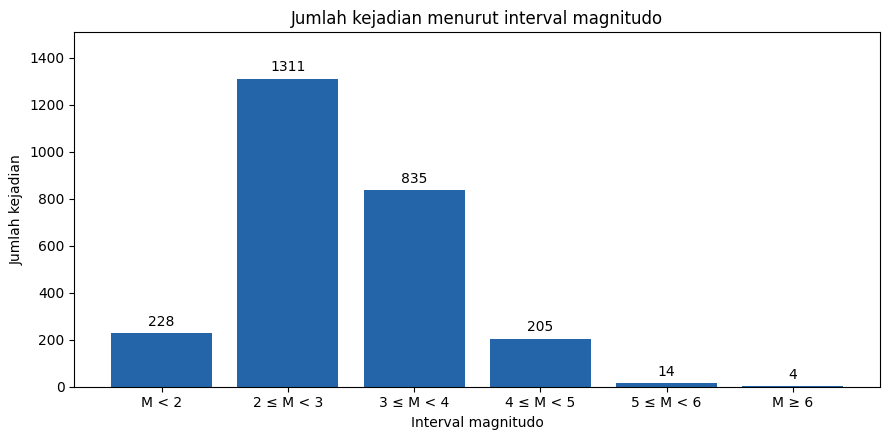

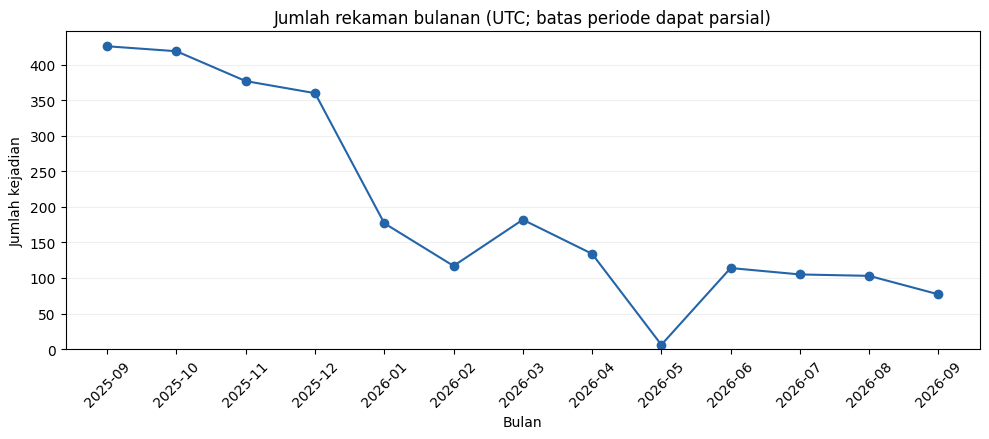

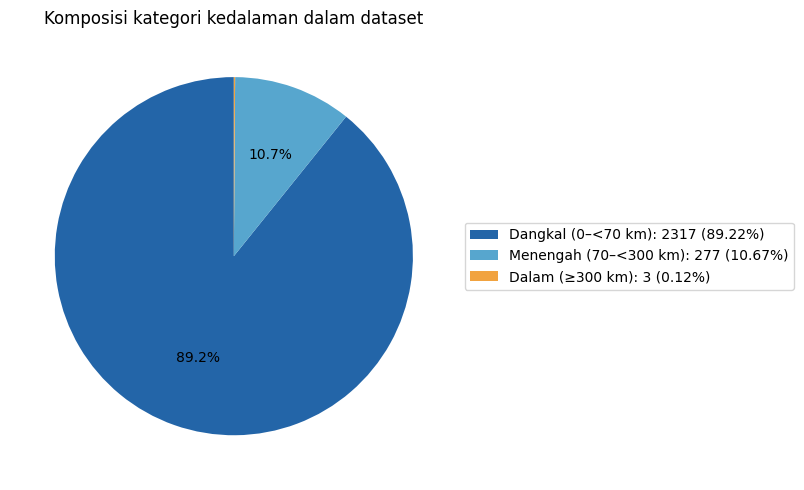

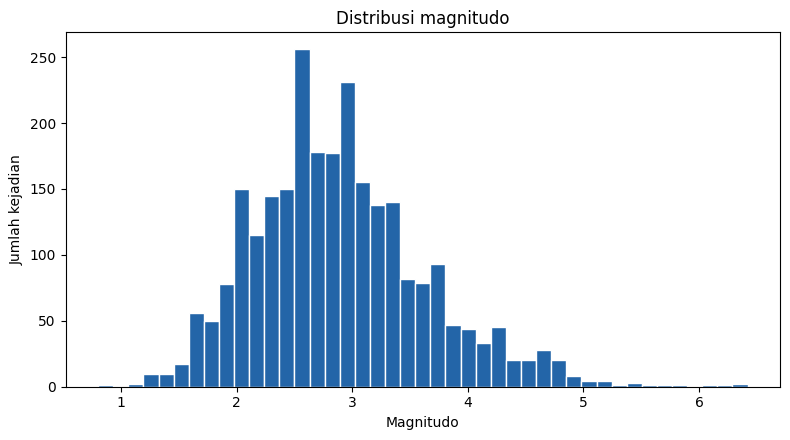

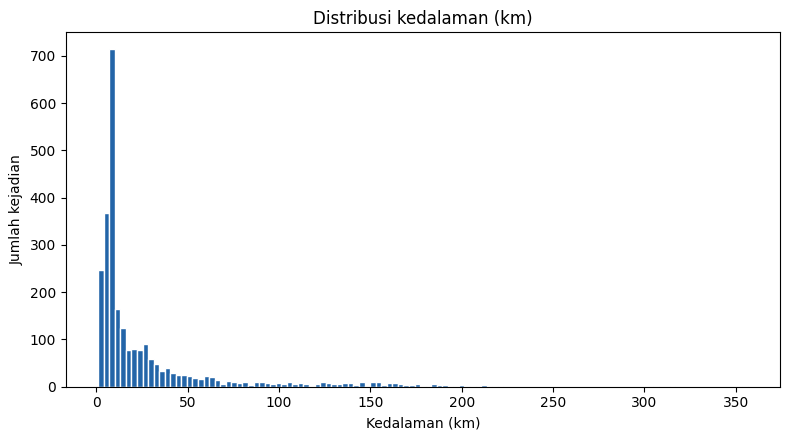

In [ ]:
if TAMPILKAN_GRAFIK == True:
    import matplotlib.pyplot as plt
    warna = '#2365a8'

    fig, ax = plt.subplots(figsize=(9,4.5))
    ax.bar(frekuensi_magnitudo['Interval magnitudo'].astype(str), frekuensi_magnitudo['Jumlah kejadian'], color=warna)
    ax.set(title='Jumlah kejadian menurut interval magnitudo', xlabel='Interval magnitudo', ylabel='Jumlah kejadian')
    ax.bar_label(ax.containers[0], padding=3)
    ax.margins(y=0.15)
    fig.tight_layout(); plt.show()

    if not bulanan.empty:
        fig, ax = plt.subplots(figsize=(10,4.5))
        ax.plot(bulanan['Bulan'], bulanan['Jumlah_kejadian'], marker='o', color=warna)
        ax.set(title='Jumlah rekaman bulanan (UTC; batas periode dapat parsial)', xlabel='Bulan', ylabel='Jumlah kejadian')
        ax.set_ylim(bottom=0)
        ax.tick_params(axis='x', rotation=45)
        ax.grid(axis='y', alpha=0.2)
        fig.tight_layout(); plt.show()

    positif = frekuensi_kedalaman.loc[frekuensi_kedalaman['Jumlah kejadian']>0]
    fig, ax = plt.subplots(figsize=(8,5))
    wedges, *_ = ax.pie(positif['Jumlah kejadian'], autopct=lambda p: f'{p:.1f}%' if p>=2 else '', startangle=90,
                       colors=['#2365a8','#57a6ce','#f1a340'])
    label_pie = [f'{kat}: {n} ({p:.2f}%)' for kat, n, p in positif.itertuples(index=False, name=None)]
    ax.legend(wedges, label_pie, loc='center left', bbox_to_anchor=(1,0.5))
    ax.set_title('Komposisi kategori kedalaman dalam dataset')
    fig.tight_layout(); plt.show()

    for c, label in [('Magnitude','Magnitudo'), ('Depth_km','Kedalaman (km)')]:
        fig, ax = plt.subplots(figsize=(8,4.5))
        ax.hist(bersih[c], bins='fd', color=warna, edgecolor='white')
        ax.set(title=f'Distribusi {label.lower()}', xlabel=label, ylabel='Jumlah kejadian')
        fig.tight_layout(); plt.show()

## 10. Tabel interpretasi berdasarkan hasil perhitungan

Semua angka berikut dihitung dari `bersih`, bukan ditulis secara manual. Hasil hanya mendeskripsikan data yang tersedia. Magnitudo dan kedalaman saja tidak cukup untuk menetapkan kerusakan, bahaya, atau risiko bagi masyarakat.


In [ ]:
hasil = []
for c, nama in [('Magnitude','Magnitudo'), ('Depth_km','Kedalaman (km)')]:
    s = bersih[c]
    skew = s.skew()
    arah = 'ke kanan' if skew>0 else ('ke kiri' if skew<0 else 'tanpa kemencengan')
    hasil.extend([
        [nama, 'Pusat', f'Mean {s.mean():.4f}; median {s.median():.4f}.'],
        [nama, 'Sebaran', f'SD {s.std(ddof=1):.4f}; IQR {(s.quantile(.75)-s.quantile(.25)):.4f}.'],
        [nama, 'Rentang observasi', f'Minimum {s.min():.4f}; maksimum {s.max():.4f}; range {(s.max()-s.min()):.4f}.'],
        [nama, 'Bentuk distribusi', f'Skewness {skew:.4f} ({arah}); excess kurtosis {s.kurt():.4f}.']
    ])
hasil.extend([
    ['Data', 'Jumlah', f'{len(bersih):,} rekaman dianalisis dari {len(raw):,} rekaman awal.'],
    ['Wilayah', 'Verifikasi', f'{len(audit_lokasi)} rekaman berlabel lokasi perlu verifikasi; dipertahankan tanpa koreksi otomatis.'],
    ['Batas kesimpulan', 'Cakupan', 'Mendeskripsikan berkas yang diberikan, termasuk lepas pantai dan Selat Sunda; bukan sensus daratan Sumatera yang terverifikasi.']
])
interpretasi = pd.DataFrame(hasil, columns=['Aspek','Fokus','Interpretasi'])
display(interpretasi)

# Pemeriksaan konsistensi hasil; tidak mencetak output tambahan jika lolos.
assert len(raw) == len(bersih) + len(data_dikeluarkan)
assert bersih[['Magnitude','Depth_km']].notna().all().all()
assert (bersih['Depth_km']>=0).all()
assert frekuensi_magnitudo['Jumlah kejadian'].sum() == len(bersih)
assert frekuensi_kedalaman['Jumlah kejadian'].sum() == len(bersih)
assert np.isclose(frekuensi_magnitudo['Persentase (%)'].sum(), 100)
assert np.isclose(frekuensi_kedalaman['Persentase (%)'].sum(), 100)
assert bulanan['Jumlah_kejadian'].sum() == len(waktu_valid)


,Aspek,Fokus,Interpretasi
0,Magnitudo,Pusat,Mean 2.8868; median 2.8000.
1,Magnitudo,Sebaran,SD 0.7462; IQR 0.9000.
2,Magnitudo,Rentang observasi,Minimum 0.8000; maksimum 6.4200; range 5.6200.
3,Magnitudo,Bentuk distribusi,Skewness 0.6743 (ke kanan); excess kurtosis 0.7993.
4,Kedalaman (km),Pusat,Mean 28.0393; median 10.0000.
5,Kedalaman (km),Sebaran,SD 39.8953; IQR 20.8900.
6,Kedalaman (km),Rentang observasi,Minimum 1.0000; maksimum 356.4300; range 355.4300.
7,Kedalaman (km),Bentuk distribusi,Skewness 2.7458 (ke kanan); excess kurtosis 8.6531.
8,Data,Jumlah,"2,597 rekaman dianalisis dari 2,597 rekaman awal."
9,Wilayah,Verifikasi,2 rekaman berlabel lokasi perlu verifikasi; dipertahankan tanpa koreksi otomatis.


## Referensi konsep dan keterbatasan

1. **Data analisis:** berkas pengguna `3TIA_01_Data_GempaBumi_BMKG(1).xlsx`, sheet `Raw_Data`; sumber dinyatakan BMKG pada `Dataset_Info`. Tidak dilakukan pengambilan rekaman baru dari internet.
2. **Sifat logaritmik magnitudo:** [USGS — Earthquake Magnitude, Energy Release, and Shaking Intensity](https://www.usgs.gov/programs/earthquake-hazards/earthquake-magnitude-energy-release-and-shaking-intensity).
3. **Batas kategori kedalaman:** [USGS — Determining the Depth of an Earthquake](https://www.usgs.gov/programs/earthquake-hazards/determining-depth-earthquake). Kesepakatan batas tepat 70 dan 300 km dijelaskan di bagian tabel frekuensi.

Modus dapat dipengaruhi pembulatan atau nilai default katalog. Flag IQR tidak membuktikan kesalahan pengukuran. Label wilayah, kelengkapan periode, jenis magnitudo, dan keterwakilan katalog membatasi interpretasi. Tidak ada SE, p-value, interval kepercayaan, uji hipotesis, korelasi inferensial, regresi, atau pengelompokan K-Means.
